<a href="https://colab.research.google.com/github/ryeggouti/morocco-world-cup-2022/blob/main/morocco_wc2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import warnings; warnings.filterwarnings("ignore")
!pip install statsbombpy -q
from statsbombpy import sb

comps = sb.competitions()
wc = comps[(comps.competition_name == "FIFA World Cup") & (comps.season_name == "2022")]
cid, sid = int(wc.competition_id.iloc[0]), int(wc.season_id.iloc[0])

matches = sb.matches(competition_id=cid, season_id=sid)
mar = matches[(matches.home_team == "Morocco") | (matches.away_team == "Morocco")]
print(mar[["match_date", "home_team", "away_team", "home_score", "away_score"]].sort_values("match_date"))


    match_date home_team away_team  home_score  away_score
7   2022-11-23   Morocco   Croatia           0           0
54  2022-11-27   Belgium   Morocco           0           2
0   2022-12-01    Canada   Morocco           1           2
46  2022-12-06   Morocco     Spain           0           0
36  2022-12-10   Morocco  Portugal           1           0
44  2022-12-14    France   Morocco           2           0
28  2022-12-17   Croatia   Morocco           2           1


   opponent  morocco_shots  opponent_shots
0   Croatia              8               5
1   Belgium             10              10
2    Canada              7               5
3     Spain              6              12
4  Portugal              9              12
5    France             13              14
6   Croatia              9              12


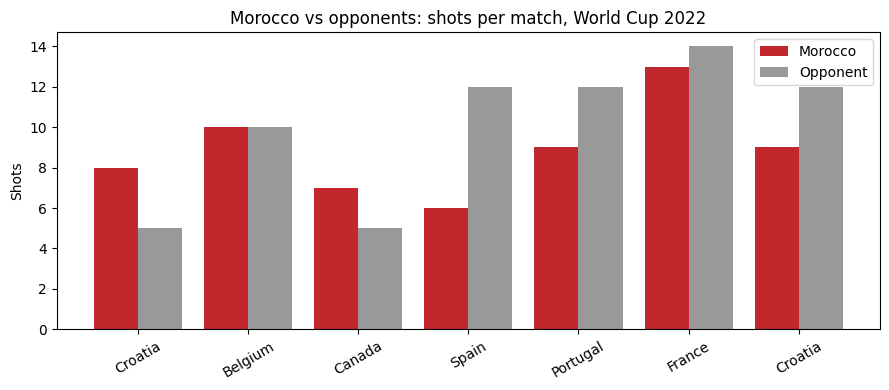

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

rows = []
for _, m in mar.sort_values("match_date").iterrows():
    ev = sb.events(match_id=m.match_id)
    shots = ev[(ev.type == "Shot") & (ev.period < 5)]
    opp = m.away_team if m.home_team == "Morocco" else m.home_team
    rows.append({
        "opponent": opp,
        "morocco_shots": (shots.team == "Morocco").sum(),
        "opponent_shots": (shots.team != "Morocco").sum(),
    })

df = pd.DataFrame(rows)
print(df)

x = range(len(df))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.2 for i in x], df.morocco_shots, width=0.4, label="Morocco", color="#C1272D")
plt.bar([i + 0.2 for i in x], df.opponent_shots, width=0.4, label="Opponent", color="#999999")
plt.xticks(list(x), df.opponent, rotation=30)
plt.ylabel("Shots")
plt.title("Morocco vs opponents: shots per match, World Cup 2022")
plt.legend()
plt.tight_layout()
plt.show()


   opponent  morocco_xg  opponent_xg
0   Croatia        0.36         0.85
1   Belgium        0.99         0.64
2    Canada        0.43         1.10
3     Spain        0.57         0.49
4  Portugal        0.97         0.74
5    France        1.23         2.00
6   Croatia        0.99         0.85


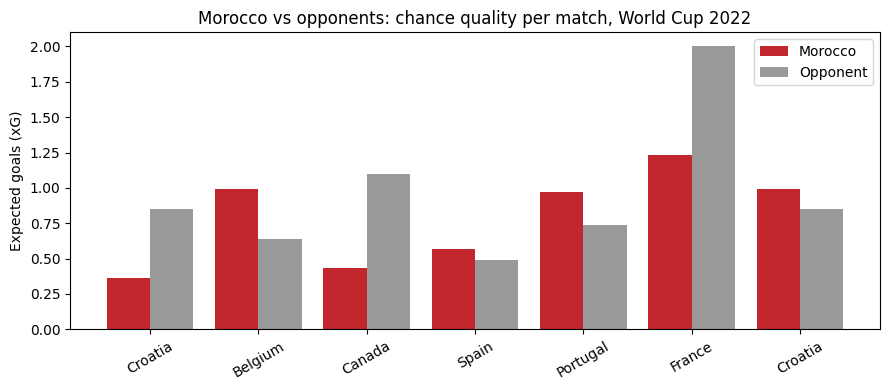

In [5]:
xg_rows = []
for _, m in mar.sort_values("match_date").iterrows():
    ev = sb.events(match_id=m.match_id)
    shots = ev[(ev.type == "Shot") & (ev.period < 5)]
    opp = m.away_team if m.home_team == "Morocco" else m.home_team
    xg_rows.append({
        "opponent": opp,
        "morocco_xg": round(shots[shots.team == "Morocco"].shot_statsbomb_xg.sum(), 2),
        "opponent_xg": round(shots[shots.team != "Morocco"].shot_statsbomb_xg.sum(), 2),
    })

xg = pd.DataFrame(xg_rows)
print(xg)

x = range(len(xg))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.2 for i in x], xg.morocco_xg, width=0.4, label="Morocco", color="#C1272D")
plt.bar([i + 0.2 for i in x], xg.opponent_xg, width=0.4, label="Opponent", color="#999999")
plt.xticks(list(x), xg.opponent, rotation=30)
plt.ylabel("Expected goals (xG)")
plt.title("Morocco vs opponents: chance quality per match, World Cup 2022")
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
events = {m.match_id: sb.events(match_id=m.match_id) for _, m in mar.iterrows()}
shots = pd.concat(events.values())
shots = shots[(shots.type == "Shot") & (shots.period < 5)]
print(len(shots), "shots loaded")


132 shots loaded


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 1.9 MB/s eta 0:00:00


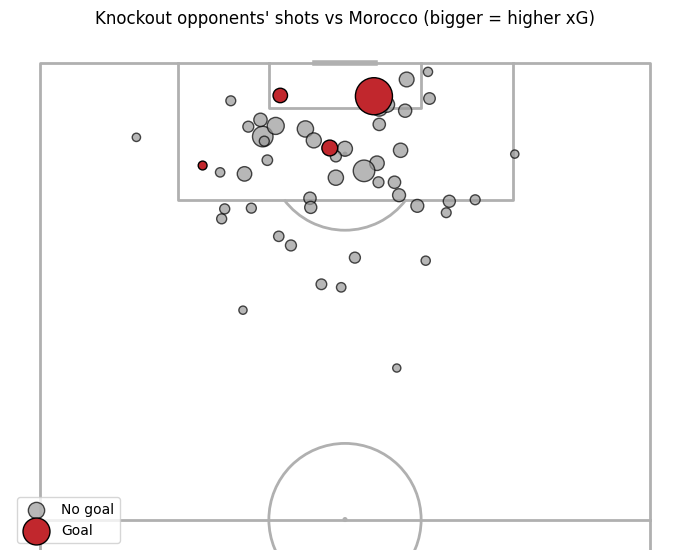

In [7]:
!pip install mplsoccer -q
from mplsoccer import VerticalPitch

ko_ids = mar[mar.match_date >= "2022-12-06"].match_id
opp = shots[shots.match_id.isin(ko_ids) & (shots.team != "Morocco")]
goals = opp[opp.shot_outcome == "Goal"]
miss = opp[opp.shot_outcome != "Goal"]

pitch = VerticalPitch(half=True, pitch_type="statsbomb")
fig, ax = pitch.draw(figsize=(7, 6))
pitch.scatter(miss.location.str[0], miss.location.str[1], s=miss.shot_statsbomb_xg * 800 + 30,
              c="#999999", edgecolors="black", alpha=0.7, ax=ax, label="No goal")
pitch.scatter(goals.location.str[0], goals.location.str[1], s=goals.shot_statsbomb_xg * 800 + 30,
              c="#C1272D", edgecolors="black", ax=ax, label="Goal")
ax.legend(loc="lower left")
ax.set_title("Knockout opponents' shots vs Morocco (bigger = higher xG)")
plt.show()


                      shots    xg  goals
player                                  
Youssef En-Nesyri        11  1.05      2
Zakaria Aboukhlal         3  0.60      1
Romain Saïss              1  0.56      1
Abderrazak Hamdallah      2  0.54      0
Achraf Dari               1  0.42      1
Yahia Attiyat allah       2  0.33      0
Sofiane Boufal            7  0.32      0
Hakim Ziyech             10  0.31      1


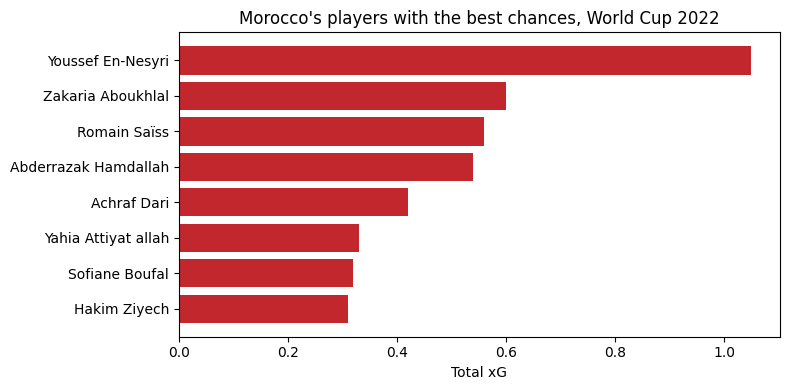

In [8]:
mor = shots[shots.team == "Morocco"]
players = mor.groupby("player").agg(
    shots=("id", "count"),
    xg=("shot_statsbomb_xg", "sum"),
    goals=("shot_outcome", lambda s: (s == "Goal").sum()),
).sort_values("xg", ascending=False).round(2)
print(players.head(8))

top = players.head(8).iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(top.index, top.xg, color="#C1272D")
plt.xlabel("Total xG")
plt.title("Morocco's players with the best chances, World Cup 2022")
plt.tight_layout()
plt.show()


In [9]:
print(mor[mor.shot_outcome == "Goal"][["match_id", "player", "minute"]])


      match_id             player  minute
3037   3857276       Hakim Ziyech       3
3042   3857276  Youssef En-Nesyri      22
3405   3869684        Achraf Dari       8
3277   3869486  Youssef En-Nesyri      41
3554   3857283       Romain Saïss      72
3557   3857283  Zakaria Aboukhlal      91
